In [30]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import pandas as pd
from pathlib import Path
import rioxarray
from rasterio.crs import CRS
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd

In [31]:
OUTPUT_CRS = CRS.from_epsg(32617)

eco = gpd.read_file("data/sandhills_shapefile/us_eco_l4_no_st.shp")
sandhills = eco[eco["US_L4CODE"] == "65c"]
sandhills = sandhills.to_crs(OUTPUT_CRS)

Text(0.5, 1.0, 'Sandhills Region Bounds (red)')

/Users/cg154122/.conda/envs/sandhills_lst_plotting/lib/python3.13/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/cg154122/.conda/envs/sandhills_lst_plotting/lib/python3.13/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/cg154122/.conda/envs/sandhills_lst_plotting/lib/python3.13/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/cg154122/.conda/envs/sandhills_lst_plotting/lib/python3.13/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/cg154122/.conda/envs/sandhills_lst_plotting/lib/python3.13/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/cg154122/.conda/envs/sandhills_lst_plotti

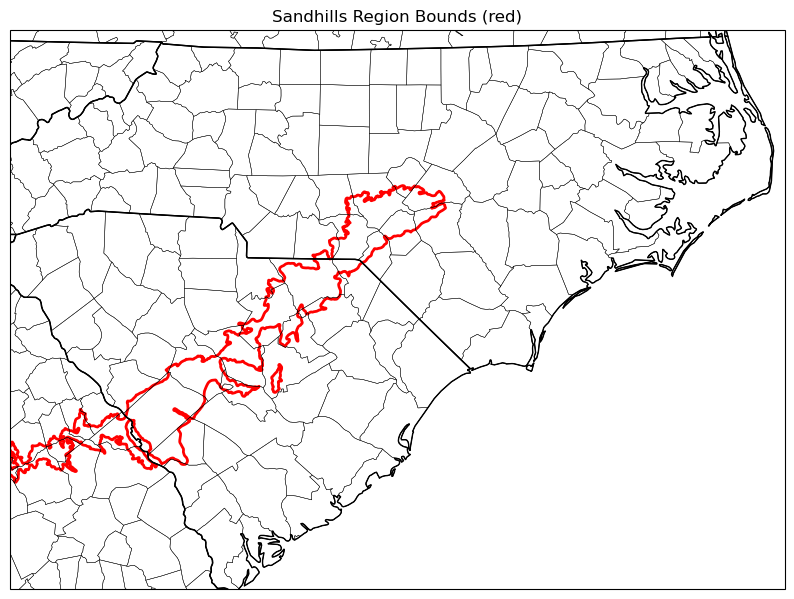

In [32]:
proj = ccrs.UTM(zone=17)
    
lonW = -83.100586
latS = 32.082575
lonE = -75.563965
latN = 36.589068

fig, ax = plt.subplots(
    figsize=(10, 8),
    subplot_kw={"projection": proj}
)

ax.add_geometries(
    sandhills.geometry,
    crs=proj,
    facecolor='none',
    edgecolor='red',
    linewidth=2
)

ax.set_extent ([lonW,lonE,latS,latN], crs=ccrs.PlateCarree())
# add boundaries
ax.add_feature(cfeature.STATES, linewidth=1)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

counties = cfeature.NaturalEarthFeature(
    category='cultural',
    name='admin_2_counties',
    scale='10m',
    facecolor='none'
)
    
ax.add_feature(counties, linewidth=0.3)
ax.set_title("Sandhills Region Bounds (red)")


In [33]:
day_datasets = []
night_datasets = []
dtr_datasets = []

files = sorted(Path('data/processed/').rglob("*.tif"))

for f in files:
    if "day" in str(f):
        da = xr.open_dataarray(f, engine="rasterio").rio.write_crs(OUTPUT_CRS)
        day_datasets.append(da)
    elif "night" in str(f):
        da = xr.open_dataarray(f, engine="rasterio").rio.write_crs(OUTPUT_CRS)
        night_datasets.append(da)
    else:
        da = xr.open_dataarray(f, engine="rasterio").rio.write_crs(OUTPUT_CRS)
        dtr_datasets.append(da)
        
    
    
day_combined = xr.concat(day_datasets, dim='new_dim')
night_combined = xr.concat(night_datasets, dim='new_dim')
dtr_combined = xr.concat(dtr_datasets, dim='new_dim')


day_average = day_combined.mean(dim='new_dim', skipna=True)
night_average = night_combined.mean(dim='new_dim', skipna=True)
dtr_average = dtr_combined.mean(dim='new_dim', skipna=True)

inside = day_average.rio.clip(sandhills.geometry, sandhills.crs)


/Users/cg154122/.conda/envs/sandhills_lst_plotting/lib/python3.13/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(


Text(0.5, 1.0, 'Outside Sandhills Control Region (red)')

/Users/cg154122/.conda/envs/sandhills_lst_plotting/lib/python3.13/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/cg154122/.conda/envs/sandhills_lst_plotting/lib/python3.13/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/cg154122/.conda/envs/sandhills_lst_plotting/lib/python3.13/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/Users/cg154122/.conda/envs/sandhills_lst_plotting/lib/python3.13/site-packages/shapely/constructive.py:246: RuntimeWarning: invalid value encountered in buffer
  return lib.buffer(
/Users/cg154122/.conda/envs/sandhills_lst_plotting/lib/python3.13/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


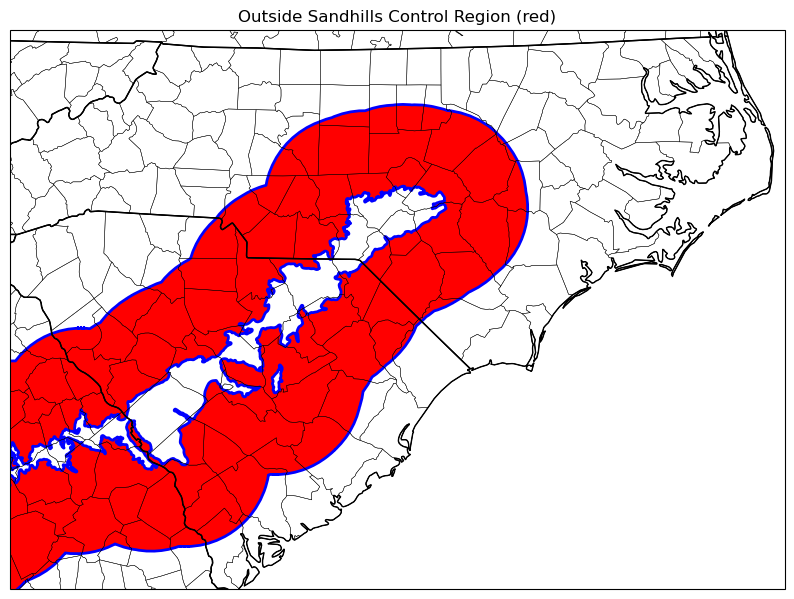

In [34]:
sandhills = sandhills.dissolve().geometry.iloc[0]

inner = sandhills.buffer(0)
outer = sandhills.buffer(75000) # meter
ring = outer.difference(sandhills)

fig, ax = plt.subplots(
    figsize=(10, 8),
    subplot_kw={"projection": proj}
)

ax.add_geometries(
    [ring],
    crs=proj,
    facecolor='red',
    edgecolor='blue',
    linewidth=2
)

ax.set_extent ([lonW,lonE,latS,latN], crs=ccrs.PlateCarree())
# add boundaries
ax.add_feature(cfeature.STATES, linewidth=1)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

counties = cfeature.NaturalEarthFeature(
    category='cultural',
    name='admin_2_counties',
    scale='10m',
    facecolor='none'
)
    
ax.add_feature(counties, linewidth=0.3)
ax.set_title("Outside Sandhills Control Region (red)")